# One Pump, a Stuck Flapper, and How Far to Trust the Numbers

The previous example tripped both pumps of the pool reactor and followed it into natural circulation through the flapper. This page asks three further questions of the same loop:

1. What happens when only one pump trips?
2. What happens when both trip and the flapper fails to open?
3. Of the times and temperatures these runs report, which converge with the solver tolerance and the output grid, and to how many digits can they be quoted?

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import rc

rc("font", family="serif", size=15)

from stream.examples.lofa import CORE, Params, both_pumps, one_pump, operating_point, stuck_flapper
from stream.examples.lofa.scenarios import flows
from stream.substances import light_water

## One pump trips

`one_pump` starts from the same operating point, ramps the head of pump B to zero at 10 s over half a second, and keeps pump A at its solved head for half an hour, at 901 output times, one every 2 s. Its `Record` has the fields of the previous page.

In [2]:
p = Params()
sol, rec = one_pump(p)
leg = rec.mdot_total / 2
print(f"status:                           {rec.status}")
print(f"reactor trip:                     {rec.t_trip:.2f} s")
print(f"check valve B shut:               {rec.t_valve_B:.0f} s")
print(f"flapper opens:                    {rec.t_open}")
print(f"leg A at the end, over its nominal: {rec.final_leg_A / leg:.3f}")
print(f"riser at the end, over nominal:   {(rec.final_leg_A + rec.final_leg_B) / rec.mdot_total:.3f}")
print(f"leg B at the end:                 {rec.final_leg_B:.2f} kg/s, {100 * rec.final_leg_B / leg:.2f} % of its nominal")
print(f"peak coolant temperature:         {rec.peak_max:.2f} °C")
print(f"margin to saturation:             {rec.margin:.2f} K")

status:                           completed
reactor trip:                     15.69 s
check valve B shut:               40 s
flapper opens:                    None
leg A at the end, over its nominal: 1.335
riser at the end, over nominal:   0.663
leg B at the end:                 -1.17 kg/s, -0.97 % of its nominal
peak coolant temperature:         64.29 °C
margin to saturation:             52.55 K


Pump A keeps its head, but the parts of the loop the two legs share, the core, the pool and the heat exchanger, now carry less flow and lose less pressure, so more of that head is left for leg A, which speeds up: at the end it carries about 1.34 times its nominal flow. The loop as a whole settles at about two thirds of its nominal flow. That is below the low-flow setpoint of 85 %, so the reactor trips, at about 15.7 s, some three seconds later than when both pumps trip. It is far above the 30 % at which the flapper opens, and the flapper never does.

Leg B's flow runs down and turns backward: pump A pushes water back through it, and its check valve holds that back to a leak. The valve counts as shut, its leg below 1 % of the nominal leg flow, at the 40 s sample, and the leak at the end is about 1.17 kg/s, about 0.97 % of the leg's nominal flow, flowing backward. With two thirds of the flow and the power down to decay heat, the coolant is never in danger: its hottest cell peaks at about 64 °C, about 53 K below saturation.

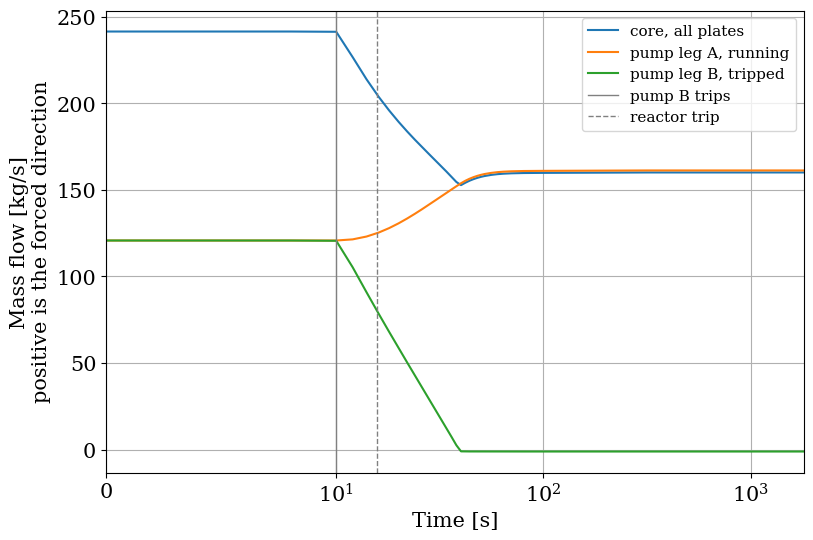

In [3]:
agr, K, refs, _ = operating_point(p)
df = flows(agr, K, refs, sol)
df["core"] = sum(CORE[k].plates * df[k] for k in CORE)


def mark(ax, events):
    for (label, t), style in zip(events.items(), ["-", "--", ":", "-."]):
        ax.axvline(t, color="gray", linewidth=1, linestyle=style, label=label)


fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(df.t, df.core, label="core, all plates")
ax.plot(df.t, df.A, label="pump leg A, running")
ax.plot(df.t, df.B, label="pump leg B, tripped")
mark(ax, {"pump B trips": p.t_pumps, "reactor trip": rec.t_trip})
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(0, sol.time[-1])
ax.set_xlabel("Time [s]")
ax.set_ylabel("Mass flow [kg/s]\npositive is the forced direction")
ax.legend(fontsize=11)
ax.grid()
plt.show()

The thin vertical lines mark the events named in the legend, here and on the next figure; the time axis is linear over the first 10 s and logarithmic after. While leg B coasts down, the core flow falls with it and leg A slowly gains. When leg B's flow reaches zero and its check valve shuts, near 40 s, the core flow stops falling and recovers a little, and from then on the core and leg A carry the same water, less the leak. Within about a minute the loop has found its new state, and it holds it for the rest of the half hour.

## A stuck flapper

`stuck_flapper` trips both pumps as on the previous page, with the flapper held shut. Without it there is no path for natural circulation through the pool: the core can only push water around among its own channels and backward through the check valves' leak. The decay heat then warms the hot channel's water until it reaches saturation. Past that point the water boils in bulk and the flow is two-phase, which this model does not represent, so the channel is built to stop the run there, with a named error, rather than integrate a state it cannot describe. `stuck_flapper` catches that error and returns the trajectory up to the stop, with the status `saturation` and the error's message in the record.

In [4]:
sol_s, rec_s = stuck_flapper(p)
print(f"status:       {rec_s.status}")
print(f"stopped at:   {rec_s.t_last:.1f} s")
print(f"reactor trip: {rec_s.t_trip:.2f} s")
print(f"flapper opens: {rec_s.t_open}")
print(f"hot group reverses: {rec_s.t_rev_hot:.0f} s, normal group: {rec_s.t_rev_normal:.0f} s, low group: {rec_s.t_rev_low}")
print(f"output times kept: {len(sol_s.time)}, last {sol_s.time[-1]:.1f} s")
at_stop = flows(agr, K, refs, sol_s).iloc[-1]
print("flows at the stop [kg/s]:", ", ".join(f"{k} {at_stop[k]:.4f}" for k in ["hot", "normal", "low", "bypass", "A", "B"]))
print()
print(rec_s.error)

status:       saturation
stopped at:   410.7 s
reactor trip: 12.49 s
flapper opens: None
hot group reverses: 300 s, normal group: 352 s, low group: None
output times kept: 207, last 410.7 s
flows at the stop [kg/s]: hot -0.0033, normal -0.0018, low 0.0015, bypass 0.0196, A -0.1016, B -0.1016

SaturationReachedError: Channel 'HotChannel' reached saturation: bulk coolant in cell(s) [1] is at/above Tsat (worst cell 1: T_bulk=117.07°C >= Tsat=117.07°C). STREAM's single-phase model ends at bulk saturation and two-phase flow is not modelled, so the solve was stopped here. Reduce power, raise pressure, or increase flow to keep the channel subcooled.


This is the outcome the case is meant to produce. The run stops at about 411 s, and the message says where: the channel `HotChannel`, cell 1 of its ten, counted from 0 at the core top, at about 117.07 °C, the saturation temperature at that cell's pressure. The reactor tripped at about 12.49 s, as with the flapper free, since the two runs are the same until the flapper would have opened. The hot group then reverses at about 300 s and the normal group at about 352 s, while the low group never does: with no path to the pool but the check valves' leak, the core recirculates within itself, and that internal loop does not carry the decay heat away. The flows at the stop show it, in the sign of the flow figures, positive downward: the hot and normal plates carry water up, the low plates and the bypass carry it down, and both pump legs leak backward through their check valves. The water leaving the hot channel upward is the hottest, which is why the cell that saturates is near the core top. `sol_s` holds the trajectory up to the stop, 2 s apart, with the stop time added as its last point.

saturation temperature at the core top: 116.84 °C
hottest coolant at the stop:              117.07 °C
margin in the record:                     -0.23 K


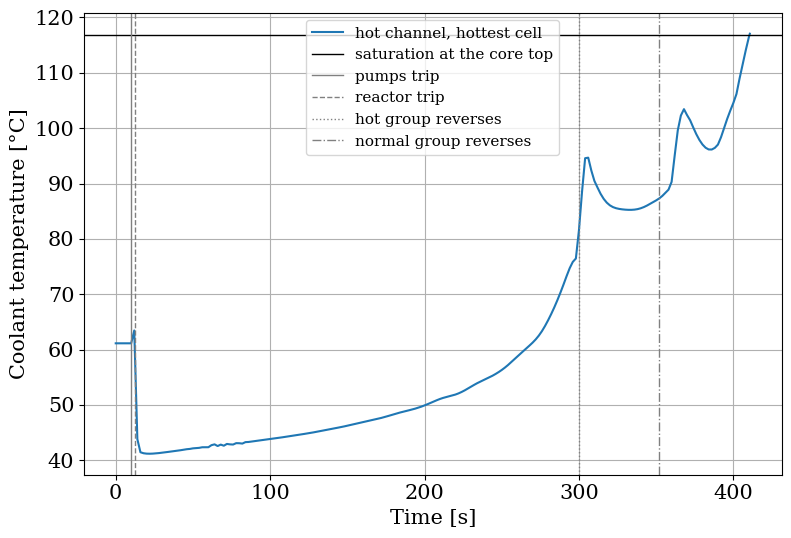

In [5]:
T_sat = float(light_water.sat_temperature(refs["p_ref"]))
T_hot = agr.at_times(sol_s, refs["channels"]["hot"], "T_cool").max(axis=1)
print(f"saturation temperature at the core top: {T_sat:.2f} °C")
print(f"hottest coolant at the stop:              {T_hot[-1]:.2f} °C")
print(f"margin in the record:                     {rec_s.margin:.2f} K")
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(sol_s.time, T_hot, label="hot channel, hottest cell")
ax.axhline(T_sat, color="black", linewidth=1, label="saturation at the core top")
mark(ax, {"pumps trip": p.t_pumps, "reactor trip": rec_s.t_trip, "hot group reverses": rec_s.t_rev_hot, "normal group reverses": rec_s.t_rev_normal})
ax.set_xlabel("Time [s]")
ax.set_ylabel("Coolant temperature [°C]")
ax.legend(fontsize=11)
ax.grid()
plt.show()

The hot channel's coolant warms briefly as the flow falls at full power, drops sharply when the rods go in, and then warms steadily: the decay heat is no longer carried away. Each reversal adds a step. When the hot group reverses, its water stands still for a moment while the plates keep heating it, and the hottest cell jumps; it jumps again a little after the normal group reverses, and from there it climbs to saturation. The curve ends about 0.2 K above the horizontal line, as the record's margin of about -0.23 K says: the line is the saturation temperature at the pressure at the core top, the stop uses the pressure at the cell, which is a little higher.

## How far to trust the event times

Every number on these pages comes from one solver tolerance, a relative `1e-4`, and one output grid. The cell below reruns the first five minutes of the both-pumps case at two tolerances, `1e-4` and `1e-5`, and two output grids, 151 and 601 times, a step of 2 s and 0.5 s. Two kinds of number should behave differently. The reactor trip and the flapper opening are events the solver locates in time, so they should not depend on the output grid, and should move with the tolerance only by the size of the solver's error. A reversal time is the first output time past the crossing and the peak coolant temperature is the largest sampled value, so both are read off the grid. The tightened runs take about two minutes in all.

In [6]:
rows = []
for a, n in ((1e-4, 151), (1e-4, 601), (1e-5, 151), (1e-5, 601)):
    _, r = both_pumps(Params(), t_end=300.0, n=n, atol_rel=a, rtol=a)
    rows.append({"tolerance": a, "outputs": n, "status": r.status, "t_trip": r.t_trip, "t_open": r.t_open, "t_rev_hot": r.t_rev_hot, "peak_max": r.peak_max})
table = pd.DataFrame(rows).set_index(["tolerance", "outputs"])
print(table.round({"t_trip": 4, "t_open": 4, "t_rev_hot": 1, "peak_max": 3}).to_string())
print()
cols = ["t_trip", "t_open", "t_rev_hot", "peak_max"]
grid = table[cols].groupby(level="tolerance").agg(lambda s: s.max() - s.min()).max()
tol = table[cols].groupby(level="outputs").agg(lambda s: s.max() - s.min()).max()
print(pd.DataFrame({"between grids": grid, "between tolerances": tol}).map(lambda v: f"{v:.2g}").to_string())
print()
print(f"margin to saturation, smallest: {T_sat - table.peak_max.max():.2f} K")

                      status   t_trip   t_open  t_rev_hot  peak_max
tolerance outputs                                                  
0.00010   151      completed  12.4923  38.8860      200.0   100.870
          601      completed  12.4923  38.8859      199.0   100.865
0.00001   151      completed  12.4948  38.8884      200.0   100.877
          601      completed  12.4948  38.8881      199.0   100.886

          between grids between tolerances
t_trip          1.2e-10             0.0025
t_open          0.00032             0.0025
t_rev_hot             1                  0
peak_max         0.0091              0.021

margin to saturation, smallest: 15.96 K


The second table gives the largest difference in each column, between the two grids at one tolerance and between the two tolerances on one grid; times are in seconds and the peak in °C.

The trip time is the same on both grids, to about 1e-10 s, and moves by about 2.5 ms when the tolerance is tightened tenfold. The opening time agrees between grids to well under a millisecond, about 0.3 ms at most, and also moves by about 2.5 ms with the tolerance. Both are what a located event should be: insensitive to where the output is sampled, and moving with the tolerance by an amount that is the solver's error at the looser one.

The hot group's reversal time does the opposite: it ignores the tolerance and moves with the grid, from 200 s on the 2 s grid to 199 s on the 0.5 s grid. The two agree, since 199 s lies in the 2 s step that ends at 200 s; the finer grid only narrows the interval in which the flow crosses. The peak coolant temperature moves by hundredths of a degree, about 0.009 °C between grids and about 0.021 °C between tolerances, both negligible against a margin to saturation of about 16 K. The sampling is not all that moves it: every time of the 151-point grid is also on the 601-point grid, so on one trajectory the finer grid could only find a higher maximum, yet at `1e-4` it finds a lower one. At this level the two grids' runs are not quite the same trajectory, and their differences are of the size of the solver's tolerance.

## What to quote

- **Trip and flapper opening:** to the hundredth of a second, about 12.49 s and about 38.89 s. The third decimal moves with the tolerance.
- **Reversal and valve times:** to the output step, as the first output time past the crossing; on the 2 s grid the hot group reverses within the 2 s before about 200 s.
- **Peak coolant temperature and margin:** to a tenth of a degree, about 100.9 °C over these five minutes, and the margin to about 16.0 K. A peak that is sharp against the output step needs a finer grid before even that digit holds.
- **The stuck-flapper stop:** an event the solver locates, like the trip, but this page has not repeated it at a second tolerance, so quote it to the second, about 411 s.

What the variations add to the previous page is qualitative and does not hang on any digit: with one pump lost the loop keeps two thirds of its flow, the reactor trips and the flapper stays shut; with the flapper stuck, the core has no path to the pool but the check valves' leak, and the hot channel reaches bulk saturation within about seven minutes.